# Domácí úkol č. 2 - 🕸 Síťová analýza PID

## 📚 Data
Jako dataset nám poslouží [otevřená data Pražské integrované dopravy](https://pid.cz/o-systemu/opendata/). Konkrétně budeme pracovat s daty [cestovních řádů](https://pid.cz/o-systemu/opendata/#h-gtfs), která jsou původně ve formátu GTFS (General Transit Feed Specification). To je formát, který využívá široká škála softwarových aplikací a kvůli tomu jej při publikaci dat využívají také veřejné dopravní agentury včetně PID.

☝️**Pozor!** Pro řešení domácí úlohy vám poskytneme už připravený dataset $D$ ve formátu `csv`. Dataset $D$ jsme pro vás sestavili z dat, která pocházejí z [cestovních řádů](https://pid.cz/o-systemu/opendata/#h-gtfs). Více informací o všech souborech a jejich atributech lze nalézt v [dokumentaci formátu GTFS](https://developers.google.com/transit/gtfs/reference).

## Zadání
> ☝️ Používejte markdown buňky! Zdůvodňujte všechny důležité kroky, popisujte vizualizace a co je z nich možné pozorovat. Za nepřehledný domácí úkol nebudou uděleny body.

Za řádné průběžné komentování a vizuální prezentaci postupu a výsledků lze získat až 4 body. Úkol řešíte jako **jednotlivci**.

**✨ Dataset**
* Načtěte si data ze souboru `d.csv`, což je již zmíněný dataset $D$, který obsahuje záznam pro každé dvě **po sobě jdoucí** zastávky nějakého spoje.
* Struktura je následující (pro zjednodušení neuvažujeme service start_date a end_date):
| stop_from | stop_from_name | stop_to | stop_to_name | depart_from | arrive_to | route_type | is_night | mon | tue | wed | thu | fri | sat | sun |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| U699Z3P | Stadion Strahov | U981Z1P | Koleje Strahov | 7:24:00 | 7:25:00 | 3 | 0 | 1 | 1 | 1 | 1 | 1 | 0 | 0 |

* Za jedinečný identifikátor zastávky můžete považovat **název zastávky**. Pozor na stejné názvy zastávek pro různé dopravní prostředky - u takových zastávek můžete uvažovat, že se jedná o jednu a tutéž stanici (v mnoha případech to i platí). 

**⚙️ Předzpracování dat**

* Atributy `depart_from` a `arrive_to` budete chtít nejspíše upravit. Obsahují totiž časové údaje delší než 24 hodin (celkem se jedná o 1.5 % záznamů). Z reference formátu GTFS (info o sloupci, z kterého vznikl `depart_from` a `arive_to`): _Arrival time at a specific stop for a specific trip on a route. … For times occurring after midnight on the service day, enter the time as a value greater than 24:00:00 in HH:MM:SS local time for the day on which the trip schedule begins._ Nicméně narazíte i na chybné časy, které začínají s hodnotou větší než 24. Všechny tyto případy můžete vyřešit pomocí **modulo 24** ☝️.


**🕸️ Základní síťová analýza** (celkem 12 bodů)

Úkolem je analyzovat síť zastávek PID. Zastávky tedy budou uzly sítě. Mezi dvěma zastávkami je orientovaná hrana, pokud jsou to dvě po sobě jdoucí zastávky nějakého spoje (existuje alespoň jeden záznam v datasetu $D$ s odpovídajícími `stop_from`, `stop_to`). Váha hrany je rovna počtu dopravních prostředků, které na dané trase za období jednoho týdne projedou.

Postupujte následovně:
* Začněte volbou libovolného balíčku pro analýzu a vizualizaci sítí (lze využít i zmíněný NetworkX),
* z datasetu $D$ vytvořte reprezentaci dat, která je vhodná pro vámi zvolený vizualizační balíček,
* vytvořte vizualizaci sítě (celkem za 4 body) - vizualizace musí být čitelná, proto můžete vizualizovat i podčást sítě (např. pro určitý dopravní prostředek, např. tramvaje (kromě vizualizace sítě lanovky nebo metra, tu neuznáváme) nebo nějaký podgraf - řešení ponecháme na vás),
* pomocí alespoň tří měr centrality analyzujte důležitost zastávek za období jednoho týdne (pondělí - neděle) a komentujte slovně, co tyto míry vzhledem ke konkrétním datům znamenají (každá míra za 2 body, celkem tedy za 6 bodů),
* vytvořte vizualizaci pro alespoň jednu míru centrality (celkem za 2 body).

**❓ Vlastní otázky** (3 body za každou otázku, celkem max. 9 bodů)

Vytvořte 3 otázky (můžete i více), založené na filtraci datasetu $D$ a odpovídejte na ně vhodnými vizualizacemi. Otázky pro inspiraci:
* Mění se důležité zastávky v závislosti na denním/nočním provozu?
* Je rozdíl ve vytíženosti zastávek během pracovního týdne/víkendu?
* ...

**🔥 Data navíc**

V souboru `stops.txt` je u každé zastávky uvedena **zeměpisná šířka a délka**. Tato data můžete využít pro rozšíření své analýzy a také vám mohou pomoci při layoutování grafu. ☝️ Pozor na stejné názvy zastávek s trochu jinou lokací pro různé dopravní prostředky. Je třeba navrhnout nějaké řešení (např. první, průměr, těžiště mnohoúhelníku apod., libovolně dle vašeho úsudku) a to zdůvodnit.

### Bodové hodnocení
Shrnutí bodů, které můžete nejvýše získat:
- 4 body za průběžné komentáře a vizuální prezentaci postupu a výsledků,
- 4 body za vizualizaci sítě,
- 6 bodů za komentovanou analýzu alespoň 3 měr centrality,
- 2 body za vizualizaci jedné z měr centrality,
- 9 bodů za definici a zodpovězení minimálně tří vlastních otázek.

Celkem lze za domácí úkol č. 2 získat maximálně 25 bodů.

## 1. Data preparation

Importing necessary libraries

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

import pandas as pd
import numpy as np
import networkx as nx
from adjustText import adjust_text
from operator import itemgetter
from scipy.spatial import ConvexHull
from geopy.distance import geodesic

Reading a dataset

In [2]:
df = pd.read_csv("d.csv")
stops_df = pd.read_csv('stops.txt', delimiter=',', header=0)
df.info()
stops_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1642433 entries, 0 to 1642432
Data columns (total 15 columns):
 #   Column          Non-Null Count    Dtype 
---  ------          --------------    ----- 
 0   stop_from       1642433 non-null  object
 1   stop_from_name  1642433 non-null  object
 2   stop_to         1642433 non-null  object
 3   stop_to_name    1642433 non-null  object
 4   depart_from     1642433 non-null  object
 5   arrive_to       1642433 non-null  object
 6   route_type      1642433 non-null  int64 
 7   is_night        1642433 non-null  int64 
 8   monday          1642433 non-null  int64 
 9   tuesday         1642433 non-null  int64 
 10  wednesday       1642433 non-null  int64 
 11  thursday        1642433 non-null  int64 
 12  friday          1642433 non-null  int64 
 13  saturday        1642433 non-null  int64 
 14  sunday          1642433 non-null  int64 
dtypes: int64(9), object(6)
memory usage: 188.0+ MB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 164

In [3]:
print(f'\nNumber of rows and columns in d.csv dataset: {df.shape}')
print(f'\nNumber of rows and columns in stops dataset: {stops_df.shape}')


Number of rows and columns in d.csv dataset: (1642433, 15)

Number of rows and columns in stops dataset: (16435, 13)


Adjusts time by applying modulo 24 to hours if they exceed 24

In [4]:
def adjust_time(time_str):
    try:
        hours, minutes, seconds = map(int, time_str.split(':'))
        hours = hours % 24
        return f"{hours:02}:{minutes:02}:{seconds:02}"
    except ValueError:
        return time_str

df['depart_from'] = df['depart_from'].apply(adjust_time)
df['arrive_to'] = df['arrive_to'].apply(adjust_time)

Display the first few rows to confirm the changes

In [5]:
df[['depart_from', 'arrive_to']].head(10)

,depart_from,arrive_to
0,04:53:00,04:54:30
1,04:54:30,04:56:00
2,04:56:00,04:59:00
3,04:59:00,05:03:00
4,04:36:00,04:38:00
5,04:38:00,04:39:00
6,04:39:00,04:40:30
7,04:40:30,04:41:30
8,05:53:00,05:54:30
9,05:54:30,05:56:00


## 2. Basic network analysis 🕸️

### 1. Visualisation of tram network 🚃

Filtered tram routes, averaged stop coordinates, updated their positions, and built a graph of the tram network.

In [6]:
tram_lines = df[df['route_type'] == 0]
unique_stops = set(tram_lines['stop_from']).union(set(tram_lines['stop_to']))
tram_locations = stops_df[stops_df['stop_id'].isin(unique_stops)]

average_coords = tram_locations.groupby('stop_name').agg({'stop_lat': 'mean', 'stop_lon': 'mean'}).reset_index()
stop_coords = average_coords.set_index('stop_name').T.to_dict('list')

for idx, data in tram_locations.iterrows():
    name = data['stop_name']
    if name in stop_coords:
        tram_locations.loc[idx, 'stop_lat'] = stop_coords[name][0]
        tram_locations.loc[idx, 'stop_lon'] = stop_coords[name][1]

tram_network = nx.Graph()

for idx, data in tram_locations.iterrows():
    tram_network.add_node(data['stop_id'], coordinates=(data['stop_lon'], data['stop_lat']))

for idx, data in tram_lines.iterrows():
    tram_network.add_edge(data['stop_from'], data['stop_to'])
    
node_positions = nx.get_node_attributes(tram_network, 'coordinates')

Graf visualisation

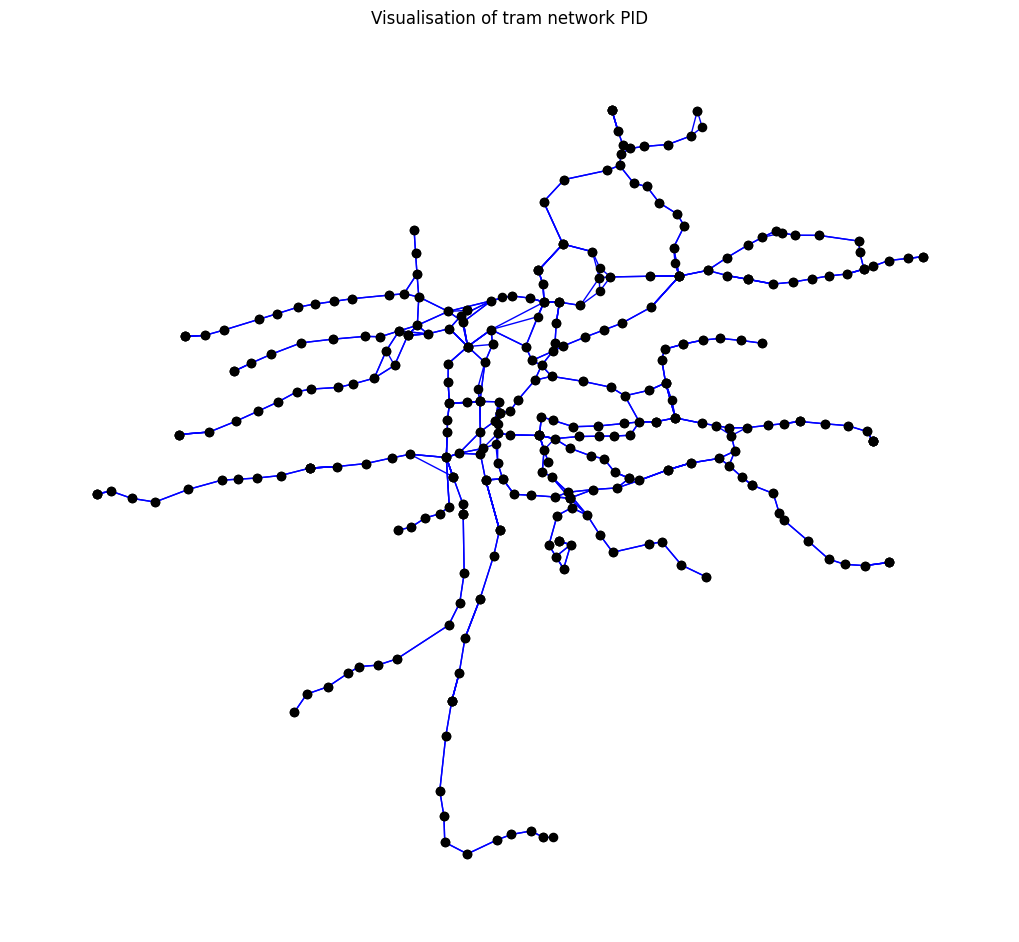

In [7]:
plt.figure(figsize=(10, 9))
nx.draw(tram_network, node_positions, node_color='black', node_size=35, edge_color='blue', linewidths=1, font_size=6)
plt.title("Visualisation of tram network PID")
plt.axis('off')
plt.show()

### 2. Сentrality measures ✅

In [8]:
G = nx.Graph()

for idx, row in tram_lines.iterrows():
    days_active = sum(row['monday':'sunday'])
    G.add_edge(row['stop_from_name'], row['stop_to_name'], weight=days_active)

#### 1. Betweenness Centrality

We calculate the betweenness centrality of each node in our Graph.

In [9]:
betweenness_centrality = nx.betweenness_centrality(G, weight='weight')
betweenness_centrality = sorted(betweenness_centrality.items(), key=lambda x: x[1], reverse=True)
betweenness_centrality[:5]

[('Malostranská', 0.4598822324628776),
 ('Újezd', 0.3861879160266257),
 ('Hellichova', 0.37985151049667176),
 ('Malostranské náměstí', 0.37884024577572967),
 ('Strossmayerovo náměstí', 0.30352022529441886)]

The top 5 stops **Malostranská**, **Újezd**, **Hellichova**, **Malostranské náměstí**, and **Strossmayerovo náměstí** have the highest centrality, meaning they are important transfer points in the tram network and help connect many routes.


#### 2. Degree Centrality

We calculate the degree centrality of each node in our Graph.

In [10]:
degree_centrality = nx.degree_centrality(G)
degree_centrality = sorted(degree_centrality.items(), key=itemgetter(1), reverse=True)
degree_centrality[:5]

[('Karlovo náměstí', 0.02857142857142857),
 ('Malostranská', 0.024999999999999998),
 ('Otakarova', 0.02142857142857143),
 ('Náměstí Bratří Synků', 0.02142857142857143),
 ('Národní divadlo', 0.02142857142857143)]

The top 5 stops with the highest degree centrality **Karlovo náměstí**, **Malostranská**, **Otakarova**, **Náměstí Bratří Synků**, and **Národní divadlo** indicate these stops connect to the largest number of other stops in the network. They serve as major hubs, making them key access points across multiple routes.


#### 3. Closeness Centrality

We calculate the closeness centrality of each node in our Graph.

In [11]:
closeness_centrality = nx.closeness_centrality(G)
closeness_centrality = sorted(closeness_centrality.items(), key=itemgetter(1), reverse=True)
closeness_centrality[:5]

[('Malostranská', 0.09978617248752673),
 ('Národní divadlo', 0.09887005649717515),
 ('Staroměstská', 0.09855684618092221),
 ('Čechův most', 0.09828009828009827),
 ('Právnická fakulta', 0.09810791871058164)]

The top 5 stops with the highest closeness centrality **Malostranská**, **Národní divadlo**, **Staroměstská**, **Čechův most**, and **Právnická fakulta** indicate these stops are, on average, the closest to all other stops in the network. This makes them easily accessible points, allowing for quick travel to other parts of the tram network.

---

We create a graph G with nodes representing tram stops (using their IDs and geographic coordinates) and edges representing connections between stops based on tram lines.



In [12]:
G = nx.Graph()
for index, row in tram_locations.iterrows():
    G.add_node(row['stop_id'], pos=(row['stop_lon'], row['stop_lat']))

for index, row in tram_lines.iterrows():
    G.add_edge(row['stop_from'], row['stop_to'])

We calculate betweenness centrality for each node, scale node sizes based on their centrality values, and visualize the graph with nodes and edges. Larger nodes represent more central stops in the network.

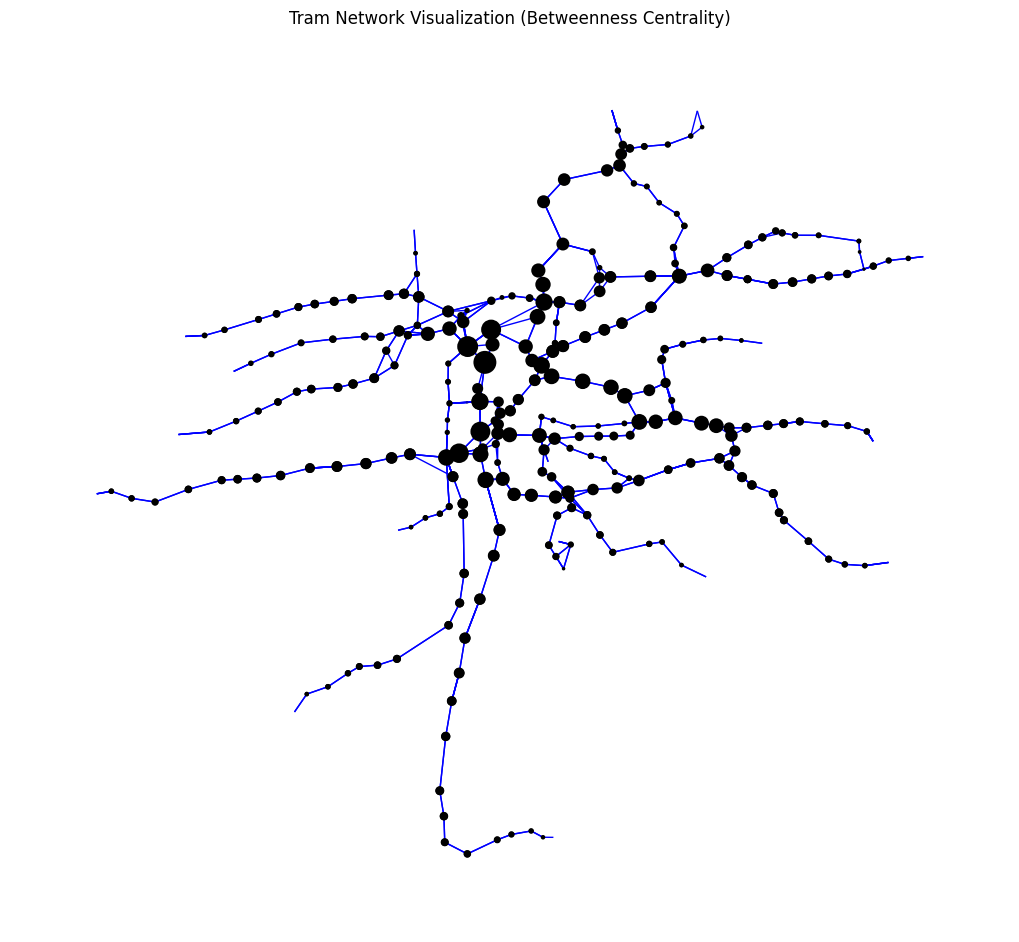

In [13]:
pos = nx.get_node_attributes(G, 'pos')
betweenness_centrality = nx.betweenness_centrality(G)

node_size = [1000 * v for v in betweenness_centrality.values()]

plt.figure(figsize=(10, 9))
nx.draw(
    G,
    pos,
    node_color='black',
    node_size=node_size,
    edge_color='blue',
    linewidths=1.5,
    font_size=8
)
plt.title("Tram Network Visualization (Betweenness Centrality)")
plt.axis('off')
plt.show()

The tram network has a radial structure with key hubs in the center handling most traffic. These hubs are critical but vulnerable, as their disruption could impact the network. Strengthening peripheral links and optimizing routes could reduce congestion and improve connectivity.








## 3. Custom questions ❓

### 1. Which stops are located at the terminal points of routes?


In [14]:
tram_lines = df[df['route_type'] == 0]

# Identify start and end stops for trams
start_stops = set(tram_lines['stop_from'])
end_stops = set(tram_lines['stop_to'])

# Identify intermediate stops (both start and end)
intermediate_stops = start_stops & end_stops

# True terminal stops are those not appearing as intermediate stops
true_terminal_stops = (start_stops | end_stops) - intermediate_stops

filtered_terminal_stops = stops_df[stops_df['stop_id'].isin(true_terminal_stops)]

unique_filtered_terminal_stops = filtered_terminal_stops.drop_duplicates(subset=['stop_name'])

print(f"Number of unique terminal tram stops: {unique_filtered_terminal_stops.shape[0]}")
print("Sample unique terminal tram stops:")
display(unique_filtered_terminal_stops[['stop_name', 'stop_lat', 'stop_lon']].head())

Number of unique terminal tram stops: 35
Sample unique terminal tram stops:


,stop_name,stop_lat,stop_lon
132,Bílá Hora,50.075546,14.322789
262,Čechovo náměstí,50.067863,14.458236
270,Nové Strašnice,50.078056,14.509384
280,Lehovec,50.106884,14.547225
325,Divoká Šárka,50.092789,14.324683


Visualize terminal tram stops

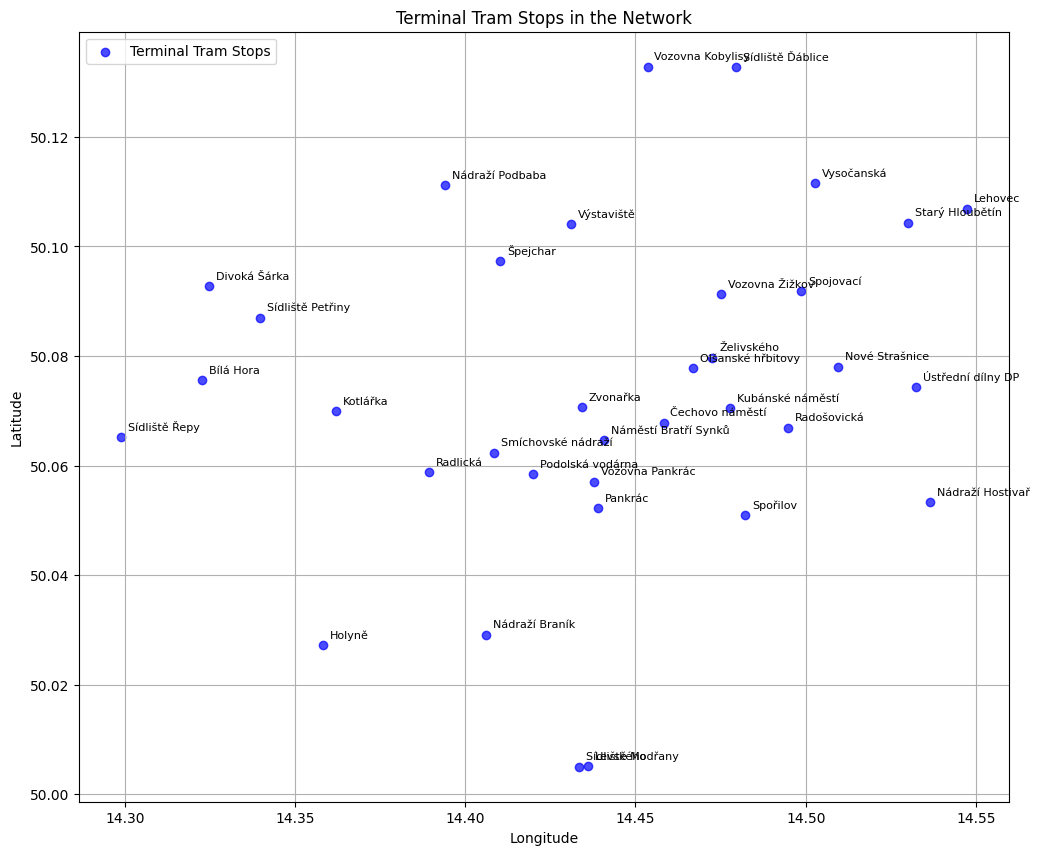

In [15]:
plt.figure(figsize=(12, 10))

plt.scatter(
    unique_filtered_terminal_stops['stop_lon'], 
    unique_filtered_terminal_stops['stop_lat'], 
    c='blue', 
    label='Terminal Tram Stops', 
    alpha=0.7
)

for _, row in unique_filtered_terminal_stops.iterrows():
    plt.annotate(
        row['stop_name'], 
        (row['stop_lon'], row['stop_lat']),
        textcoords="offset points", 
        xytext=(5, 5),  # Offset label slightly to avoid overlap
        fontsize=8, 
        color='black'
    )

plt.title('Terminal Tram Stops in the Network')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.legend()
plt.grid(True)
plt.show()

### 2. What is the distance between the southernmost and northernmost stops?

In [16]:
# Find the southernmost and northernmost stops based on latitude
southernmost_stop = stops_df.loc[stops_df['stop_lat'].idxmin()]  
northernmost_stop = stops_df.loc[stops_df['stop_lat'].idxmax()]  

# Extract coordinates for both stops
southernmost_coords = (southernmost_stop['stop_lat'], southernmost_stop['stop_lon'])
northernmost_coords = (northernmost_stop['stop_lat'], northernmost_stop['stop_lon'])

distance = geodesic(southernmost_coords, northernmost_coords).kilometers

print(f"The distance between the southernmost and northernmost stops is {distance:.2f} kilometers.")
print(f"Southernmost stop: {southernmost_stop['stop_name']} at coordinates {southernmost_coords}")
print(f"Northernmost stop: {northernmost_stop['stop_name']} at coordinates {northernmost_coords}")

The distance between the southernmost and northernmost stops is 216.68 kilometers.
Southernmost stop: Třeboň,aut.nádr. at coordinates (np.float64(49.007847), np.float64(14.765294))
Northernmost stop: Rumburk,Bytex 01 at coordinates (np.float64(50.951221), np.float64(14.554912))


### 3. Which tram stop can be considered "central" based on its average distance to all other stops?

Builds a tram network graph, calculates average shortest-path distances for each stop, and identifies the most central stops. 


In [17]:
def calculate_distance(coord1, coord2):
    return geodesic(coord1, coord2).kilometers

tram_network = nx.Graph()

node_positions = {
    row['stop_name']: (row['stop_lon'],row['stop_lat'])
    for _, row in stops_df.iterrows()
}

for _, row in tram_lines.iterrows():
    stop_from = row['stop_from_name']
    stop_to = row['stop_to_name']
    
    if stop_from in node_positions and stop_to in node_positions:
        coord_from = node_positions[stop_from]
        coord_to = node_positions[stop_to]
        
        distance = calculate_distance(coord_from, coord_to)
        
        tram_network.add_edge(stop_from, stop_to, weight=distance)

average_distances = {}

for node in tram_network.nodes():
    total_distance = 0
    reachable_nodes = 0
    
    shortest_paths = nx.single_source_dijkstra_path_length(tram_network, node, weight='weight')
    
    for target, dist in shortest_paths.items():
        total_distance += dist
        reachable_nodes += 1
    
    average_distances[node] = total_distance / reachable_nodes if reachable_nodes > 0 else float('inf')



This code identifies the central tram stops with the smallest average distance to all others, prints their names and distances, and visualizes the tram network. Central stops are highlighted in cyan, labels are displayed slightly offset, and the network graph is shown with edges and nodes.


Central tram stop based on average distance:
Stop: Lazarská, Average Distance: 6.72 km


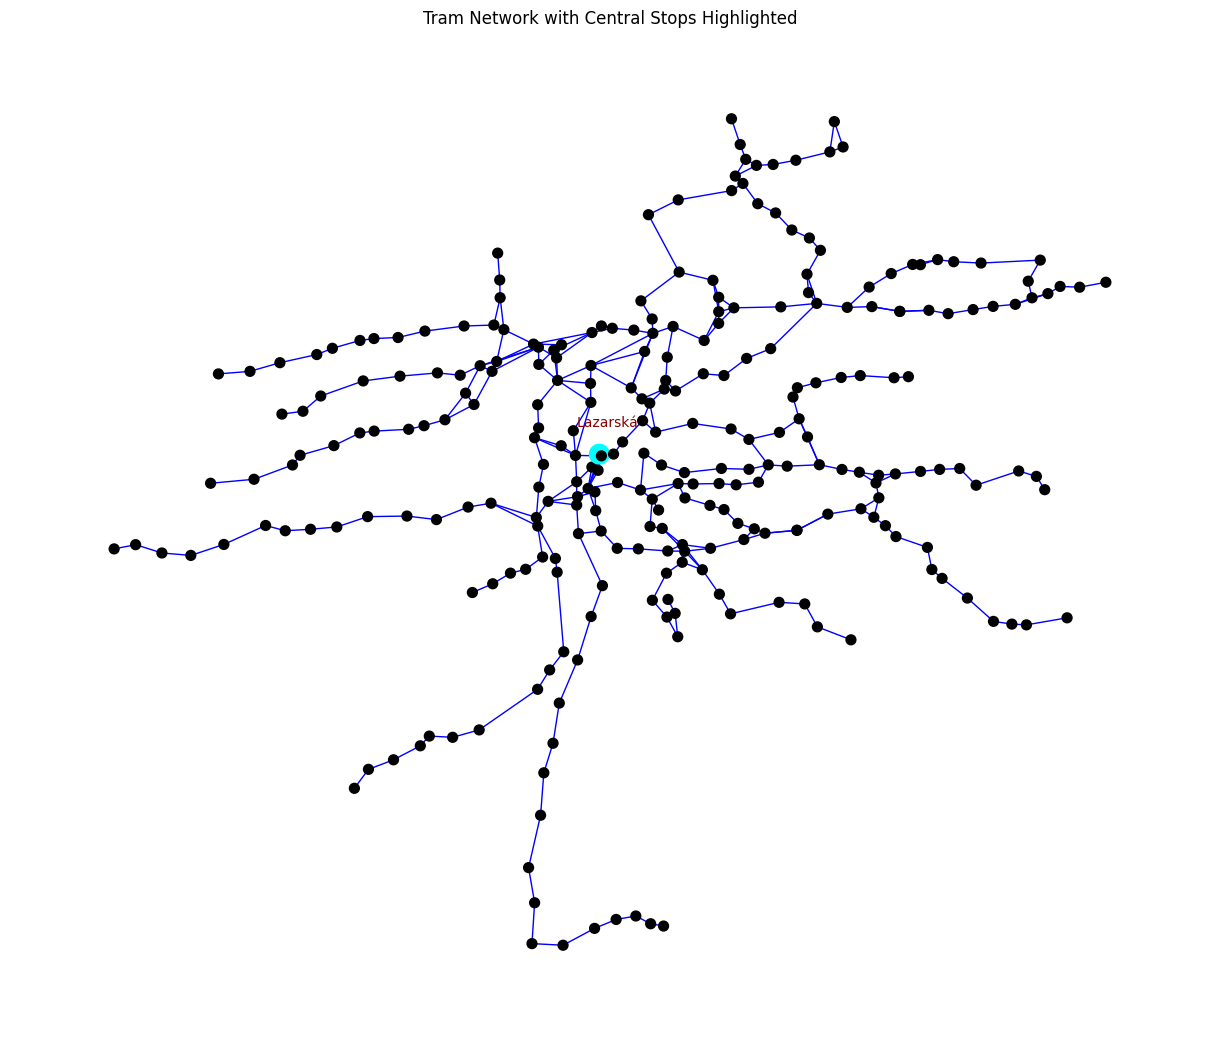

In [23]:
min_avg_distance = min(average_distances.values())
central_stop = [stop for stop, avg_dist in average_distances.items() if avg_dist == min_avg_distance]
print("Central tram stop based on average distance:")
for stop in central_stop:
    print(f"Stop: {stop}, Average Distance: {average_distances[stop]:.2f} km")

label_positions = {node: (x + 0.002, y + 0.005) for node, (x, y) in node_positions.items() if node in central_stop}

plt.figure(figsize=(12, 10))
pos = node_positions  

nx.draw(
    tram_network, pos,
    node_color=['cyan' if node in central_stop else 'black' for node in tram_network.nodes()],
    node_size=[200 if node in central_stop else 50 for node in tram_network.nodes()],
    edge_color='blue', linewidths=1, with_labels=False  
)

labels = {node: node for node in central_stop}
nx.draw_networkx_labels(tram_network, label_positions, labels=labels, font_size=10, font_color='darkred')

plt.title("Tram Network with Central Stops Highlighted")
plt.axis('off')
plt.show()

The result identifies **Lazarská** as the central tram stop, with an average shortest-path distance of **6.72 km** to all other reachable stops in the network.


## The end.